In [9]:
#| echo: false
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import FancyArrowPatch, Circle, Arc
from math import gcd
from functools import reduce

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
rng = np.random.default_rng(20)


def draw_chain(P, pos, ax, labels=None, r=0.09, edge_labels=None):
    """Draw a transition graph: nodes at pos, an arrow i -> j whenever p_ij > 0.
    Edge labels are p_ij by default, or edge_labels[i][j] (a string) if given."""
    m = len(P)
    labels = labels or [str(i + 1) for i in range(m)]
    lab_of = (lambda i, j: edge_labels[i][j]) if edge_labels is not None \
             else (lambda i, j: f"{P[i][j]:g}")
    ax.set_aspect("equal"); ax.axis("off")
    for i in range(m):
        ax.add_patch(Circle(pos[i], r, fc="#e8f1fb", ec="C0", lw=1.5, zorder=3))
        ax.text(*pos[i], labels[i], ha="center", va="center", fontsize=13, zorder=4)
    for i in range(m):
        for j in range(m):
            if P[i][j] <= 0:
                continue
            x0, y0 = pos[i]; x1, y1 = pos[j]
            if i == j:
                ax.add_patch(Arc((x0, y0 + r + 0.045), 0.1, 0.12, theta1=-30, theta2=210, ec="k", lw=1.2, zorder=2))
                ax.add_patch(FancyArrowPatch((x0 - 0.052, y0 + r + 0.075), (x0 - 0.045, y0 + r + 0.02),
                                             arrowstyle="-|>", mutation_scale=9, color="k", zorder=2))
                ax.text(x0, y0 + r + 0.135, lab_of(i, j), ha="center", fontsize=10)
            else:
                d = np.array([x1 - x0, y1 - y0]); d = d / np.hypot(*d)
                a = np.array([x0, y0]) + d * r; b = np.array([x1, y1]) - d * r
                rad = 0.25 if P[j][i] > 0 else 0.0
                ax.add_patch(FancyArrowPatch(a, b, arrowstyle="-|>", mutation_scale=14, color="k",
                                             connectionstyle=f"arc3,rad={rad}", lw=1.2, zorder=2))
                mid = (a + b) / 2
                dx, dy = b - a
                if rad == 0:
                    lab = mid + np.array([0.0, 0.045])
                else:
                    lab = mid + 0.5 * rad * np.array([dy, -dx]) * 1.5
                ax.text(*lab, lab_of(i, j), ha="center", va="center", fontsize=10,
                        bbox=dict(fc="white", ec="none", pad=0.5))
    xs = [p[0] for p in pos]; ys = [p[1] for p in pos]
    ax.set_xlim(min(xs) - 0.2, max(xs) + 0.2); ax.set_ylim(min(ys) - 0.25, max(ys) + 0.35)

# Discrete-Time Markov Chains

## Motivation

::: {.callout-note}
## Recall

- **Bernoulli process:** trials are independent, so the future is independent of the past.
- **Poisson process:** the fresh-start property (and memorylessness of the exponential) says the future is independent of the past.
:::

. . .

But many systems have memory:

- Whether a machine works tomorrow depends on whether it works today.
- Tomorrow's weather depends on today's weather.
- A gambler's fortune after the next bet depends on the current fortune.


. . .

::: {.callout-tip}
## Key idea

In a **Markov model**, the past affects the future only **through the current state**. Given the present, the future is independent of the past.
:::

## Markov Models

::: {.callout-note}
## A discrete-time Markov model is specified by

1. A **state space** $\mathcal S=\{1,2,\ldots,m\}$ (finite). Let $X_n$ be the state at time $n=0,1,2,\ldots$
2. **Transition probabilities**. Whenever the state happens to be $i$, there is probability $p_{ij}$ that the next state is equal to $j$: 
$$p_{ij}=P(X_{n+1}=j\mid X_n=i),\qquad i,j\in\mathcal S.$$
:::

. . .

::: {.callout-warning}
## Note

The next state $X_{n+1}$ depends on the past only through the value of the present state $X_n$.
:::

## Markov chain

::: {.callout-note}
## Definition (Markov property)

A sequence $X_0,X_1,X_2,\ldots$ is a **Markov chain** if for all times $n$ and all states $i,j \in \mathcal{S}$, and all possible sequences of prior states $i_0,\ldots,i_{n-1}$,
$$P(X_{n+1}=j\mid X_n=i,\,X_{n-1}=i_{n-1},\ldots,X_0=i_0)=P(X_{n+1}=j\mid X_n=i)=p_{ij}.$$
:::

. . .

Conditioned on the present $X_n$, the future $X_{n+1},X_{n+2},\ldots$ is independent of the past $X_0,\ldots,X_{n-1}$.


## Transition probability matrix and graph

::: {.callout-note}
## Transition probability matrix

All of the elements of a Markov chain model can be encoded in a **transition probability matrix** $P$, where
$$P=\begin{bmatrix}p_{11}&p_{12}&\cdots&p_{1m}\\p_{21}&p_{22}&\cdots&p_{2m}\\\vdots&&\ddots&\vdots\\p_{m1}&p_{m2}&\cdots&p_{mm}\end{bmatrix}$$
Row $i$ is the PMF of the next state given that we are currently in state $i$.
:::

. . .

What is the sum of entries in a single row?

. . .

::: {.callout-tip}
## Transition graph

Draw one node per state and an arrow $i\to j$ labeled $p_{ij}$ whenever $p_{ij}>0$. The outgoing labels from each node sum to 1.
:::

### Example: machine breakdown and repair

::: {.callout-warning}
## Example

A machine is either **working** or **broken down** on a given day.

If it is working, it breaks down the next day with probability $b$, and continues working with probability $1-b$. If it is broken down, it is repaired and working the next day with probability $r$, and continues to be broken down with probability $1-r$.
:::

. . .

Let's label the states: 1 = working, 2 = broken down.  The transition matrix is: 

$$P=\begin{bmatrix}1-b&b\\r&1-r\end{bmatrix}$$


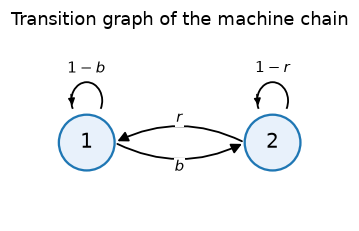

In [10]:
#| fig-height: 2.4
b, r = 0.2, 0.5   # only used to decide which edges exist and for the row-sum check
P = np.array([[1 - b, b],
              [r, 1 - r]])
assert np.allclose(P.sum(axis=1), 1)

edge_labels = [["$1-b$", "$b$"],
               ["$r$",   "$1-r$"]]

pos = [(0.0, 0.0), (0.6, 0.0)]
fig, ax = plt.subplots(figsize=(6, 2.2))
draw_chain(P.tolist(), pos, ax, edge_labels=edge_labels)
ax.set_title("Transition graph of the machine chain")
plt.tight_layout(); plt.show()

## Path probability

::: {.callout-note}
## Path probability

By the multiplication rule and the Markov property, the probability of a particular sequence of states, given the starting state, is the product of the transition probabilities along the path:
$$
\begin{aligned}
P(X_0 = i_0, X_1 = i_1, \cdots, X_n = i_n) &= P(X_n = i_n \mid X_0 = i_0, \cdots, X_{n-1} = i_{n-1})P(X_0 = i_0, \cdots, X_{n-1} = i_{n-1}) 
\\&= p_{i_{n-1}i_n} P(X_0 = i_0, \cdots, X_{n-1} = i_{n-1}) = \cdots 
\\&= P(X_0 = i_0)p_{i_0 i_1} p_{i_1 i_2} \cdots p_{i_{n-1} i_n}.
\end{aligned}$$
:::

. . .

::: {.callout-warning}
## Example (machine chain)

Starting with a working machine, what is the probability that the machine is broken the next two days and then repaired (working on day 3)?
:::

. . .

$$P(X_1=2,X_2=2,X_3=1\mid X_0=1)=p_{12}\,p_{22}\,p_{21}=b\,(1-r)\,r.$$

## $n$-step transition probabilities

::: {.callout-note}
## Definition

The **$n$-step transition probability**,
$$r_{ij}(n)=P(X_n=j\mid X_0=i)$$
is the probability of being in state $j$ after $n$ steps, starting from state $i$. By convention $r_{ij}(0)=1$ if $i=j$ and $0$ otherwise, and $r_{ij}(1)=p_{ij}$.
:::

. . .

::: {.callout-tip}
## Chapman–Kolmogorov equation

The $n$-step transition probabilities can be calculated recursively as
$$r_{ij}(n)=\sum_{k=1}^m r_{ik}(n-1)\,p_{kj}, \quad \text{ for } n > 1, \text{ and all } i,j \in \mathcal{S},$$
starting from $r_{ij}(1) = p_{ij}$.
In matrix form, the $n$-step transition matrix is the $n$th matrix power: $R(n)=P^n$.
:::

. . .

Proof: $P(X_n = j \mid X_0 = i) = \sum_{k=1}^m P(X_{n-1} = k \mid X_0 = i) P(X_n = j \mid X_{n-1} = k, X_0 = i) = \sum_{k=1}^m r_{ik}(n-1) p_{kj}.$

---

::: {.callout-warning}
## Example (machine chain)

Starting from a working machine, what is the probability that it is working two days later? Broken two days later?
:::

. . .

Starting from a working machine, there are two ways to be working after two days: $1\to1\to1$ or $1\to2\to1$. So
$$r_{11}(2)=p_{11}p_{11}+p_{12}p_{21}=(1-b)^2+b\,r.$$
Likewise, there are two ways to be broken after two days: $1\to1\to2$ or $1\to2\to2$, so
$$r_{12}(2)=p_{11}p_{12}+p_{12}p_{22}=(1-b)\,b+b\,(1-r).$$

# Classification of States

## Accessible, recurrent, and transient states

::: {.callout-note}
## Definitions

- State $j$ is **accessible** from state $i$ if $r_{ij}(n)>0$ for some $n\ge0$. That is, there is a path in the transition graph from $i$ to $j$.

- Let $A(i)$ denote the set of states accessible from $i$. States $i$ and $j$ **communicate** if each is accessible from the other.

- State $i$ is **recurrent** if for every $j\in A(i)$ we also have $i\in A(j)$: from anywhere we can get to from $i$, we can get back.

- State $i$ is **transient** if it is not recurrent, i.e. there is some $j\in A(i)$ from which $i$ cannot be reached again.
:::



. . .

- A **transient** state is visited only finitely many times: once the chain reaches a state from which $i$ is inaccessible, it can never return.
- A **recurrent** state is visited infinitely many times.


## Recurrent classes

::: {.callout-note}
## Definition

If $i$ is recurrent, the states in $A(i)$ all communicate with $i$ and with each other. The set $A(i)$ is called a **recurrent class**: a collection of recurrent states that communicate with each other and with no other state.
:::

. . .

Why must these states all communicate with one another? Why do we know that none of these states may communicate with a state outside of $A(i)$?  Why do we know that they cannot communicate with a transient state?    

. . .

::: {.callout-tip}
## Facts

- Every recurrent state belongs to exactly one recurrent class.
- Once the chain enters a recurrent class, it **never leaves** it.
- Two states in the same recurrent class have the same set $A(\cdot)$.
- At least one recurrent state must be accessible from any transient state.
:::

## Markov chain decomposition

::: {.callout-tip}
## Decomposition

The state space of any (finite) Markov chain can be decomposed into

- one or more **recurrent classes**, and
- possibly some **transient states**.
:::

. . .

A recurrent state is accessible from all states in its class, but is not accessible from recurrent states in other classes.

. . .

A transient state is not accessible from any recurrent state.

. . .

At least one, possibly more, recurrent states are accessible from a given transient state.

---

Check that you understand which of these states are transient and recurrent!

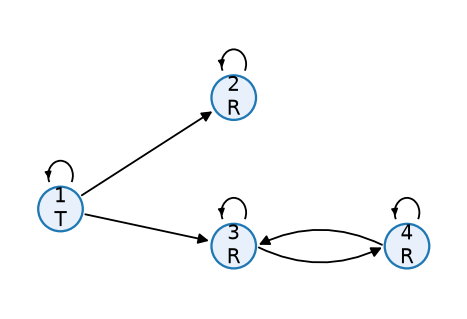

In [15]:
#| fig-height: 3
P = np.array([[0.4, 0.3, 0.3, 0.0],
              [0.0, 1.0, 0.0, 0.0],
              [0.0, 0.0, 0.6, 0.4],
              [0.0, 0.0, 0.7, 0.3]])
assert np.allclose(P.sum(axis=1), 1)
m = len(P)

# accessibility: A[i, j] is True if j can be reached from i in >= 0 steps
A = np.linalg.matrix_power(np.eye(m) + (P > 0), m - 1) > 0

# i is recurrent iff every state accessible from i can get back to i
recurrent = [i for i in range(m) if all(A[j, i] for j in range(m) if A[i, j])]

# node labels include the state type
labels = [f"{i + 1}\n" + ("R" if i in recurrent else "T") for i in range(m)]

# blank edge labels: every entry is an empty string
edge_labels = [[""] * m for _ in range(m)]

pos = [(0.0, 0.0), (0.7, 0.45), (0.7, -0.15), (1.4, -0.15)]
fig, ax = plt.subplots(figsize=(9, 3))
draw_chain(P.tolist(), pos, ax, labels=labels, edge_labels=edge_labels)
plt.tight_layout(); plt.show()

## Long-term Behavior

(a) Once the state enters (or starts in) a class of recurrent states, it stays within that class; since all states in the class communicate, all states in the class will be visited an infinite number of times.

(b) If the initial state is transient, then the state trajectory contains an initial portion consisting of transient states and a final portion consisting of recurrent states from the same class.

### Example: machine failure, repair, replacement

::: {.callout-warning}
## Example: classifying the states of a chain

A factory has an old machine that is currently working (state 1). Each day it keeps working with probability $0.4$, is scrapped for good without a replacement with probability $0.3$ (state 2), or is replaced by a new machine with probability $0.3$ (state 3, new and working). The new machine is covered by a service contract that keeps it in service indefinitely: it alternates between **working** (state 3) and **in repair** (state 4). A working new machine breaks down with probability $0.4$, and a machine in repair is fixed with probability $0.7$.

$$P=\begin{bmatrix}0.4&0.3&0.3&0\\0&1&0&0\\0&0&0.6&0.4\\0&0&0.7&0.3\end{bmatrix}$$

- Which states can be reached from each state? (What is $A(i)$ for each $i$?)
- Which states are transient and recurrent?  What are the recurrent classes?
:::

---

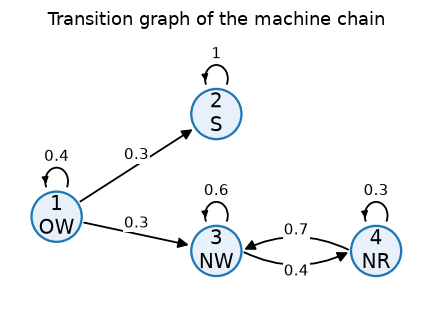

In [19]:
#| fig-height: 3
P = np.array([[0.4, 0.3, 0.3, 0.0],
              [0.0, 1.0, 0.0, 0.0],
              [0.0, 0.0, 0.6, 0.4],
              [0.0, 0.0, 0.7, 0.3]])
assert np.allclose(P.sum(axis=1), 1)

labels = ["1\nOW", "2\nS", "3\nNW", "4\nNR"]

pos = [(0.0, 0.0), (0.7, 0.45), (0.7, -0.15), (1.4, -0.15)]
fig, ax = plt.subplots(figsize=(9, 3))
draw_chain(P.tolist(), pos, ax, labels=labels, r=0.11)
ax.set_title("Transition graph of the machine chain")
plt.tight_layout(); plt.show()

. . .

::: {.callout-note}
## Answers

- $A(1)=\{1,2,3,4\}$, $A(2)=\{2\}$, and $A(3)=A(4)=\{3,4\}$.
- State 1 is **transient**: $2\in A(1)$ but $1\notin A(2)$. Once the old machine is scrapped or replaced, it never comes back.
- State 2 is **recurrent**: it is absorbing, so $\{2\}$ is a recurrent class (a scrapped machine stays scrapped).
- States 3 and 4 are **recurrent** and communicate, so $\{3,4\}$ is a second recurrent class (the new machine cycles between working and in repair).
:::

## Periodicity

::: {.callout-note}
## Definition

A recurrent class is **periodic** if its states can be grouped into $d>1$ disjoint subsets $S_1,\ldots,S_d$ such that every transition from a state in $S_k$ leads to a state in $S_{k+1}$ (with $S_{d+1}=S_1$). Otherwise it is **aperiodic**.
:::

. . .

In a periodic class, the chain moves through $S_1\to S_2\to\cdots\to S_d\to S_1\to\cdots$ in a deterministic cyclic order. For states $i$ in the class, $r_{ii}(n)=0$ unless $n$ is a multiple of $d$.

. . .

::: {.callout-tip}
## Note

If a recurrent class contains a state with a self-transition ($p_{ii}>0$), the class is **aperiodic**.
:::

. . .

A recurrent class $R$ is *aperiodic* if and only if there exists a time $n$ such that $r_{ij}(n) > 0$ for all $i,j \in R.$